<a href="https://colab.research.google.com/github/Dynamodeep/Toy-Project-LogisticRegression/blob/main/end_to_end_ML.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [75]:
import numpy as np
import pandas as pd

# Loading our CSV file:

In [76]:
df=pd.read_csv("/content/placement.csv")

In [14]:
df.head()

,Unnamed: 0,cgpa,iq,placement
0,0,6.8,123.0,1
1,1,5.9,106.0,0
2,2,5.3,121.0,0
3,3,7.4,132.0,1
4,4,5.8,142.0,0


In [15]:
df.shape

(100, 4)

In [77]:
df=df.iloc[:,1:]


## Updated the old dataframe by removing the column unnamed

In [17]:
df.head()

,cgpa,iq,placement
0,6.8,123.0,1
1,5.9,106.0,0
2,5.3,121.0,0
3,7.4,132.0,1
4,5.8,142.0,0


## Exploratory Data Analysis


In [78]:
import matplotlib.pyplot as plt


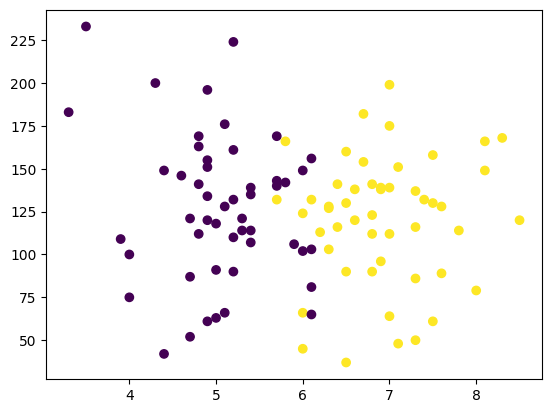

In [79]:
plt.scatter(df["cgpa"],df["iq"],c=df["placement"])

In [80]:
X=df.iloc[:,[0,1]]
y=df.iloc[:,-1]

In [22]:
X

,cgpa,iq
0,6.8,123.0
1,5.9,106.0
2,5.3,121.0
3,7.4,132.0
4,5.8,142.0
...,...,...
95,4.3,200.0
96,4.4,42.0
97,6.7,182.0
98,6.3,103.0


In [66]:
y

,placement
0,1
1,0
2,0
3,1
4,0
...,...
95,0
96,0
97,1
98,1


In [81]:
from sklearn.model_selection import train_test_split
X_train,X_test,Y_train,Y_test=train_test_split(X,y,test_size=0.1)

In [49]:
X_train

,cgpa,iq
47,5.2,161.0
57,6.5,130.0
33,6.0,149.0
68,4.0,75.0
64,7.0,64.0
...,...,...
73,4.9,61.0
19,5.2,132.0
48,6.6,138.0
95,4.3,200.0


In [50]:
X_test

,cgpa,iq
3,7.4,132.0
86,5.1,128.0
61,7.3,137.0
8,6.1,156.0
38,6.5,160.0
85,5.8,166.0
18,4.0,100.0
35,6.8,90.0
80,4.9,196.0
79,6.5,90.0


In [59]:
Y_train

,placement
39,0
53,1
47,0
59,0
13,1
...,...
54,1
46,0
14,0
49,0


In [52]:
Y_test

,placement
3,1
86,0
61,1
8,0
38,1
85,1
18,0
35,1
80,0
79,1


In [82]:
from sklearn.preprocessing import StandardScaler
sc=StandardScaler()
X_train=sc.fit_transform(X_train)
X_test=sc.transform(X_test)


In [43]:
X_train

array([[-1.03695381, -0.29131598],
       [-0.77480256, -1.46680152],
       [-0.07573258, -0.44464018],
       [-0.77480256,  0.11754855],
       [ 0.27380241,  0.11754855],
       [ 0.4485699 , -0.85350472],
       [-0.68741882, -0.34242405],
       [ 0.88548864, -0.29131598],
       [ 0.01165117, -1.46680152],
       [-0.94957006, -1.59457169],
       [ 0.88548864, -1.51790959],
       [-0.86218631, -0.13799178],
       [ 0.4485699 ,  0.93527763],
       [-1.73602379, -0.59796438],
       [ 0.6233374 ,  0.78195343],
       [-0.77480256,  1.34414216],
       [ 0.09903491,  0.83306149],
       [-0.68741882, -0.85350472],
       [ 1.40979113, -0.87905875],
       [ 1.23502363,  0.21976469],
       [-0.94957006, -0.08688371],
       [ 1.40979113,  0.11754855],
       [-0.51265132, -0.41908615],
       [ 0.09903491,  0.21976469],
       [ 1.14763989, -1.87566606],
       [-0.86218631, -1.54346362],
       [-0.16311633,  0.47530502],
       [ 0.71072115, -0.29131598],
       [-0.86218631,

In [30]:
X_test

array([[-1.03695381,  1.01193973],
       [ 0.4485699 ,  0.16865662],
       [-1.12433755, -1.82455799],
       [ 0.97287239, -1.92677413],
       [-1.03695381,  0.44975099],
       [ 0.7981049 , -0.70018052],
       [-1.2117213 ,  0.57752116],
       [ 0.88548864,  0.39864292],
       [ 0.88548864,  1.93188493],
       [ 0.7981049 ,  0.37308889]])

In [44]:
Y_train

,placement
59,0
9,0
1,0
86,0
63,1
...,...
24,0
90,1
62,0
97,1


In [83]:
from sklearn.linear_model import LogisticRegression
model=LogisticRegression()
model.fit(X_train,Y_train)

LogisticRegression()

In [84]:
Y_predict=model.predict(X_test)

In [37]:
Y_test

,placement
34,0
57,1
94,0
5,1
51,0
66,1
39,0
32,1
26,1
11,1


In [85]:
from sklearn.metrics import accuracy_score
accuracy_score(Y_test,Y_predict)

0.9

<Axes: >

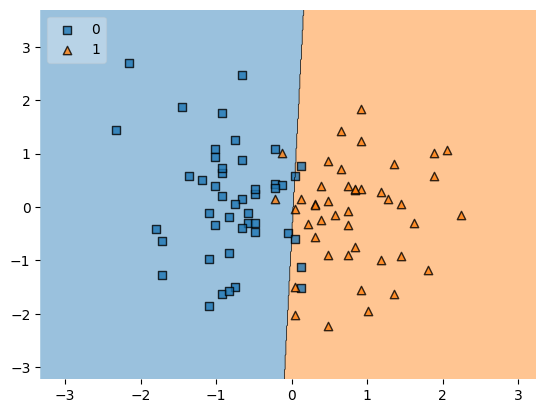

In [87]:
from mlxtend.plotting import plot_decision_regions
plot_decision_regions(X_train, Y_train.values, clf=model, legend=2)

In [89]:
import pickle

In [90]:
pickle.dump(model,open("model.pkl","wb"))